# Series Trigonométricas de Fourier y Análisis de Armónicas
Este cuaderno de Jupyter permite calcular paso a paso los coeficientes de Fourier ($a_0, a_n, b_n$), la tabla de armónicas (amplitud $C_n$ y fase $\phi_n$) y sus respectivas gráficas, funcionando **100% offline**.

## Paso 1: Importación de librerías e inicialización de renderizado LaTeX
Al usar `sp.init_printing()`, SymPy mostrará las fórmulas e integrales en notación matemática elegante.

In [2]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math

# Habilitar representación LaTeX bonita en Jupyter
sp.init_printing(use_latex='mathjax')

## Paso 2: Definición de variables y función periódica $f(t)$
Aquí defines la variable simbólica `t`, el índice `n` y la función por partes $f(t)$.

In [52]:
# Variables simbólicas
t = sp.Symbol('t', real=True)
n = sp.Symbol('n', integer=True, positive=True)

# Definir la función f(t) y el intervalo [t_a, t_b]
# Ejemplo: Rectificador de media onda en [0, 2*pi]
t_a = 0
t_b = 2 * sp.pi
f = sp.Piecewise(
    ( ((0.25*t**2)),(t >= 0) & (t <= 2*sp.pi)),
    ((0), (t >= 2*sp.pi) & (t <= 4*sp.pi))
)

# Periodo T y frecuencia fundamental w0
T = t_b - t_a
w0 = 2 * sp.pi / T

display(Math(r'f(t) = ' + sp.latex(f)))
display(Math(r'T = ' + sp.latex(T) + r', \quad \omega_0 = ' + sp.latex(w0)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Paso 3: Cálculo Simbólico de Coeficientes ($a_0$, $a_n$, $b_n$)
Calculamos las integrales de Fourier en notación simbólica y las simplificamos.

In [53]:
# Coeficiente a0 (Componente DC)
a0 = sp.simplify((1 / T) * sp.integrate(f, (t, t_a, t_b)))

# Coeficiente an
an = sp.simplify((2 / T) * sp.integrate(f * sp.cos(n * w0 * t), (t, t_a, t_b)))

# Coeficiente bn
bn = sp.simplify((2 / T) * sp.integrate(f * sp.sin(n * w0 * t), (t, t_a, t_b)))

display(Math(r'a_0 = ' + sp.latex(a0)))
display(Math(r'a_n = ' + sp.latex(an)))
display(Math(r'b_n = ' + sp.latex(bn)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Paso 4: Expresión General de la Serie de Fourier
Mostramos la serie de Fourier en forma de sumatoria simbólica.

In [23]:
serie_latex = r'f(t) \sim ' + sp.latex(a0) + r' + \sum_{n=1}^{\infty} \left[ \left(' + sp.latex(an) + r'\right)\cos(n\omega_0 t) + \left(' + sp.latex(bn) + r'\right)\sin(n\omega_0 t) \right]'
display(Math(serie_latex))

<IPython.core.display.Math object>

## Paso 5: Expresión Ampliada de la Serie de Fourier
Mostramos la serie de Fourier en forma ampliada.

Se calcula a partir de lo que esta dentro de las funciones trigonometricas sen(t<--aca) o cos(t<--aca) - forma 2* pi *f *t

In [25]:
# -------------------------------------------------------------------------
# CÓDIGO PARA LA SERIE EXPANDIDA (Términos explícitos)
# -------------------------------------------------------------------------
N_terminos = 6  # Número de términos a expandir explícitamente

expr_expandida = a0

for i in range(1, N_terminos + 1):
    # Sustituir n por el número de armónica i
    an_i = sp.simplify(an.subs(n, i))
    bn_i = sp.simplify(bn.subs(n, i))
    
    # Agregar término con coseno si es distinto de 0
    if an_i != 0:
        expr_expandida += an_i * sp.cos(i * w0 * t)
        
    # Agregar término con seno si es distinto de 0
    if bn_i != 0:
        expr_expandida += bn_i * sp.sin(i * w0 * t)

# Mostrar en notación matemática elegante
display(Math(r'f(t) \approx ' + sp.latex(expr_expandida)))

<IPython.core.display.Math object>

## Paso 6: Cálculo de Armónicas ($C_n$ y $\phi_n$)
Convertimos a la forma compacta Amplitud-Fase:
$$f(t) = a_0 + \sum_{n=1}^{\infty} C_n \cos(n \omega_0 t - \phi_n)$$
donde $C_n = \sqrt{a_n^2 + b_n^2}$ y $\phi_n = \text{atan2}(b_n, a_n)$.

In [26]:
N_armonicas = 10
tabla_armonicas = []

print(f"{'n':<4} | {'a_n':<12} | {'b_n':<12} | {'Amplitud C_n':<15} | {'Fase phi_n (rad)':<18} | {'Fase phi_n (°)':<18}")
print("-" * 88)

for i in range(1, N_armonicas + 1):
    try:
        an_v = float(an.subs(n, i).evalf())
    except Exception:
        an_v = 0.0
    try:
        bn_v = float(bn.subs(n, i).evalf())
    except Exception:
        bn_v = 0.0
    
    cn_v = np.hypot(an_v, bn_v)
    phi_r = np.arctan2(bn_v, an_v)
    phi_d = np.degrees(phi_r)
    
    tabla_armonicas.append({'n': i, 'an': an_v, 'bn': bn_v, 'Cn': cn_v, 'phi_rad': phi_r, 'phi_deg': phi_d})
    print(f"{i:<4} | {an_v:<12.5f} | {bn_v:<12.5f} | {cn_v:<15.5f} | {phi_r:<18.5f} | {phi_d:<18.2f}°")

n    | a_n          | b_n          | Amplitud C_n    | Fase phi_n (rad)   | Fase phi_n (°)    
----------------------------------------------------------------------------------------
1    | 0.00000      | -1.00000     | 1.00000         | -1.57080           | -90.00            °
2    | 0.00000      | -0.50000     | 0.50000         | -1.57080           | -90.00            °
3    | 0.00000      | -0.33333     | 0.33333         | -1.57080           | -90.00            °
4    | 0.00000      | -0.25000     | 0.25000         | -1.57080           | -90.00            °
5    | 0.00000      | -0.20000     | 0.20000         | -1.57080           | -90.00            °
6    | 0.00000      | -0.16667     | 0.16667         | -1.57080           | -90.00            °
7    | 0.00000      | -0.14286     | 0.14286         | -1.57080           | -90.00            °
8    | 0.00000      | -0.12500     | 0.12500         | -1.57080           | -90.00            °
9    | 0.00000      | -0.11111     | 0.11111    

## Paso 7: Reconstrucción Gráfica y Espectros de Armónicas
Graficamos la función original, las sumas parciales de Fourier para varios términos $N$, y los espectros discretos de Amplitud y Fase.

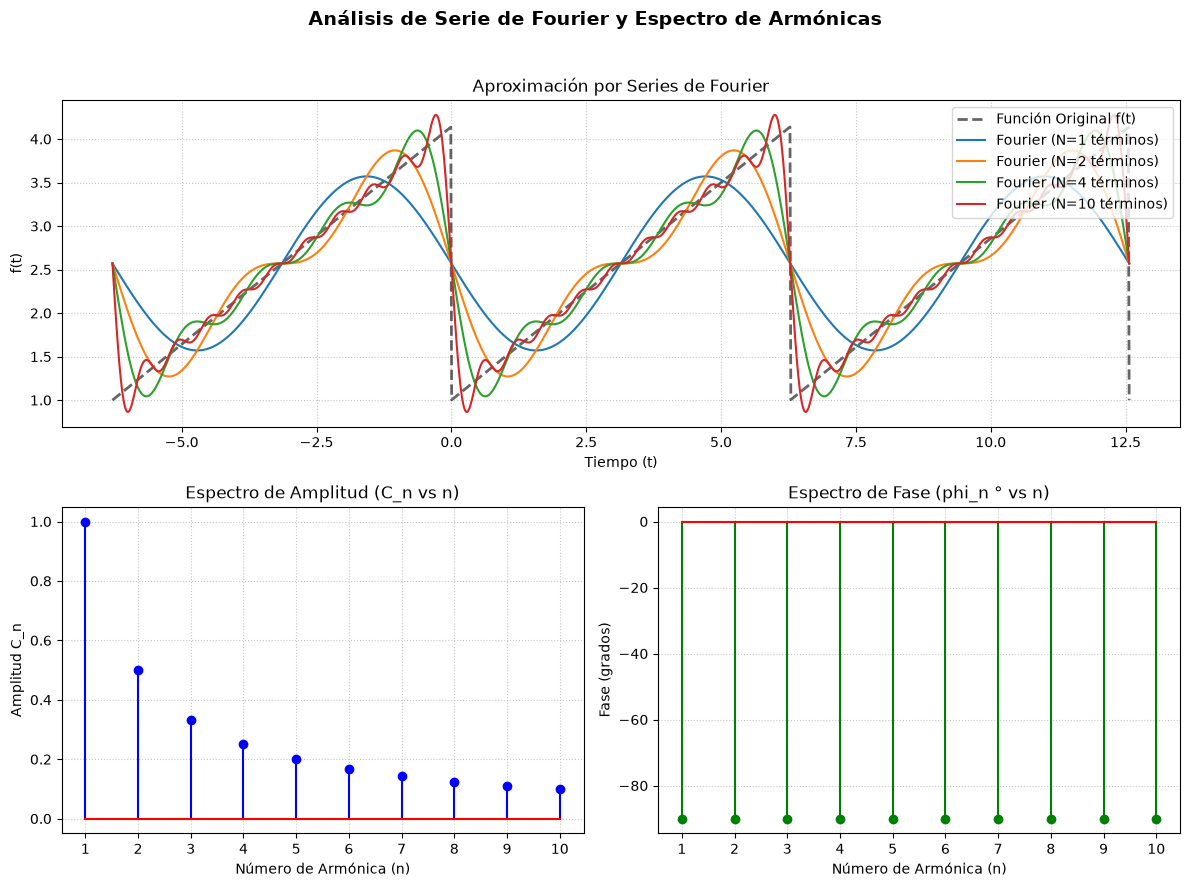

In [27]:
t_a_num = float(sp.sympify(t_a).evalf())
t_b_num = float(sp.sympify(t_b).evalf())
T_num = float(sp.sympify(T).evalf())
w0_num = float(sp.sympify(w0).evalf())
a0_num = float(sp.sympify(a0).evalf())

# Vector de tiempo en 3 periodos
t_vec = np.linspace(t_a_num - T_num, t_b_num + T_num, 1200)

# Evaluación periódica de f(t)
f_lam = sp.lambdify(t, f, modules=['numpy'])
t_mod = (t_vec - t_a_num) % T_num + t_a_num
f_orig = f_lam(t_mod)

def eval_fourier(t_arr, N_terms):
    f_sum = np.full_like(t_arr, a0_num, dtype=float)
    for i in range(1, N_terms + 1):
        an_i = tabla_armonicas[i-1]['an'] if i <= len(tabla_armonicas) else float(an.subs(n, i).evalf())
        bn_i = tabla_armonicas[i-1]['bn'] if i <= len(tabla_armonicas) else float(bn.subs(n, i).evalf())
        f_sum += an_i * np.cos(i * w0_num * t_arr) + bn_i * np.sin(i * w0_num * t_arr)
    return f_sum

fig = plt.figure(figsize=(12, 9))
fig.suptitle('Análisis de Serie de Fourier y Espectro de Armónicas', fontsize=14, fontweight='bold')

# 1. Reconstrucción
ax1 = plt.subplot(2, 1, 1)
ax1.plot(t_vec, f_orig, 'k--', label='Función Original f(t)', alpha=0.6, linewidth=2)

for N in [1, 2, 4, 10]:
    f_app = eval_fourier(t_vec, N)
    ax1.plot(t_vec, f_app, label=f'Fourier (N={N} términos)')

ax1.set_title('Aproximación por Series de Fourier')
ax1.set_xlabel('Tiempo (t)')
ax1.set_ylabel('f(t)')
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend(loc='upper right')

# 2. Espectro Amplitud
ax2 = plt.subplot(2, 2, 3)
ns = [item['n'] for item in tabla_armonicas]
cns = [item['Cn'] for item in tabla_armonicas]
ax2.stem(ns, cns, linefmt='b-', markerfmt='bo', basefmt='r-')
ax2.set_title('Espectro de Amplitud (C_n vs n)')
ax2.set_xlabel('Número de Armónica (n)')
ax2.set_ylabel('Amplitud C_n')
ax2.set_xticks(ns)
ax2.grid(True, linestyle=':', alpha=0.7)

# 3. Espectro Fase
ax3 = plt.subplot(2, 2, 4)
phis = [item['phi_deg'] for item in tabla_armonicas]
ax3.stem(ns, phis, linefmt='g-', markerfmt='go', basefmt='r-')
ax3.set_title('Espectro de Fase (phi_n ° vs n)')
ax3.set_xlabel('Número de Armónica (n)')
ax3.set_ylabel('Fase (grados)')
ax3.set_xticks(ns)
ax3.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## EJEMPLO DE CALCULO DE STF CON VARIABLES - NO NUMEROS

In [8]:
import sympy as sp
from IPython.display import display, Math

# 1. Definir TODAS las incógnitas/variables simbólicas con suposiciones
t = sp.Symbol('t', real=True)
n = sp.Symbol('n', integer=True, positive=True)

# Incógnitas generales del problema:
A = sp.Symbol('A', positive=True)  # Amplitud (siempre positiva)
T = sp.Symbol('T', positive=True)  # Periodo (siempre positivo)

# Frecuencia angular en términos de T
w0 = 2 * sp.pi / T

# 2. Definir f(t) simbólica (Ejemplo: Onda cuadrada que vale A de 0 a T/2, y -A de T/2 a T)
f = sp.Piecewise(
    (A, (t >= 0) & (t < T/2)),
    (-A, (t >= T/2) & (t < T))
)

# 3. Calcular integrales simbólicas
a0 = sp.simplify((1 / T) * sp.integrate(f, (t, 0, T)))
an = sp.simplify((2 / T) * sp.integrate(f * sp.cos(n * w0 * t), (t, 0, T)))
bn = sp.simplify((2 / T) * sp.integrate(f * sp.sin(n * w0 * t), (t, 0, T)))

# 4. Mostrar resultados simetricos en LaTeX
display(Math(r'a_0 = ' + sp.latex(a0)))
display(Math(r'a_n = ' + sp.latex(an)))
display(Math(r'b_n = ' + sp.latex(bn)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

# Ejercicio variables: Serie de Fourier de Media Onda Senoidal Rectificada (Simbólica)
Calcularemos los coeficientes $a_0$, $a_n$, $b_n$ y la serie expandida para una señal de amplitud $A$ y periodo $T_0$.

In [1]:
import sympy as sp
from IPython.display import display, Math

# Activar renderizado gráfico de fórmulas en Jupyter
sp.init_printing(use_latex='mathjax')

In [2]:
# Variables del tiempo y del índice
t = sp.Symbol('t', real=True)
n = sp.Symbol('n', integer=True, positive=True)

# Parámetros generales del problema (amplitud y periodo)
A = sp.Symbol('A', positive=True)
T0 = sp.Symbol('T_0', positive=True)

# Frecuencia fundamental w0 en función del periodo T0
w0 = 2 * sp.pi / T0

display(Math(r'\text{Frecuencia fundamental: } \omega_0 = ' + sp.latex(w0)))

<IPython.core.display.Math object>

In [3]:
# Función de media onda senoidal
f = sp.Piecewise(
    (A * sp.sin(w0 * t), (t >= 0) & (t < T0 / 2)),
    (0, (t >= T0 / 2) & (t < T0))
)

display(Math(r'f(t) = ' + sp.latex(f)))

<IPython.core.display.Math object>

In [8]:
# Integrales de Fourier integrando sobre [0, T0]
a0 = sp.simplify((1 / T0) * sp.integrate(f, (t, 0, T0)))
an = sp.simplify((2 / T0) * sp.integrate(f * sp.cos(n * w0 * t), (t, 0, T0)))
bn = sp.simplify((2 / T0) * sp.integrate(f * sp.sin(n * w0 * t), (t, 0, T0)))

display(Math(r'a_0 = ' + sp.latex(a0)))
display(Math(r'a_n = ' + sp.latex(an)))
display(Math(r'b_n = ' + sp.latex(bn)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [13]:
# Reconstrucción explícita de los primeros N términos
N_terminos = 6
expr_expandida = a0

for i in range(1, N_terminos + 1):
    an_i = sp.simplify(an.subs(n, i))
    bn_i = sp.simplify(bn.subs(n, i))
    
    if an_i != 0:
        expr_expandida += an_i * sp.cos(i * w0 * t)
    if bn_i != 0:
        expr_expandida += bn_i * sp.sin(i * w0 * t)

display(Math(r'f(t) \approx ' + sp.latex(expr_expandida)))

<IPython.core.display.Math object>